# Chapter 57: New Trade Theory, Firm Selection, Scale, and Geography

This notebook reruns four worked examples from the chapter: the home-market effect, scale economies between identical countries, Melitz selection, and the gravity response to a trade-cost cut. Every example is hypothetical, as in the book; a few extra input values are added for comparison, and producer allocations and post-trade weights are assumed outcomes, not derived equilibria.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def average_cost(F, c, q):
    """Average cost (F + c q) / q."""
    return (F + c * q) / q


def home_market_accounting(demand_H, demand_I, n_total, n_H, q):
    """Demand share, producer share and net trade for an assumed producer allocation.

    home-market-effect (chapter 57): s_E = 900/(900 + 600) = 0.60, s_N = 8/12 = 0.6667,
    Harbor output 8(125) = 1,000, net exports 1,000 - 900 = 100; Inland 4(125) = 500, net -100.
    The allocation n_H is an assumed equilibrium outcome, not derived.
    """
    s_E = demand_H / (demand_H + demand_I)
    s_N = n_H / n_total
    out_H = n_H * q
    out_I = (n_total - n_H) * q
    return {"s_E": s_E, "s_N": s_N, "gap": s_N - s_E, "output_H": out_H, "output_I": out_I,
            "net_exports_H": out_H - demand_H, "net_exports_I": out_I - demand_I,
            "world_output": out_H + out_I, "world_demand": demand_H + demand_I}


def gravity_ratio(t0, t1, sigma):
    """Constant-resistance gravity ratio X'/X = (t1/t0)^(1 - sigma).

    gravity-equation-of-trade (chapter 57): (1.22/1.30)^(1-4) = (1.30/1.22)^3 = 1.2099;
    160(1.2099) = 193.58; cost cut 6.15 percent, export rise 20.99 percent.
    """
    return (t1 / t0) ** (1.0 - sigma)


plt.rcParams.update(HOUSE_RC)


production = SimpleNamespace(average_cost=average_cost)


trade = SimpleNamespace(home_market_accounting=home_market_accounting, gravity_ratio=gravity_ratio)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'home-market-effect': {'demand_H': 900,
                        'demand_I': 600,
                        'n_total': 12,
                        'n_H': 8,
                        'q': 125,
                        'tau': 1.15,
                        's_E': 0.6,
                        's_N': 0.6667,
                        'output_H': 1000,
                        'net_exports_H': 100,
                        'output_I': 500,
                        'benchmark_n_H': 6},
 'new-trade-theory-scale-mechanism': {'F': 90,
                                      'c': 2,
                                      'varieties': 4,
                                      'q_autarky': 75,
                                      'q_integrated': 150,
                                      'C_autarky': 240,
                                      'AC_autarky': 3.2,
                                      'C_integrated': 390,
                                      'AC_integrated': 2.6,
                                      'world_cost_autarky': 1920,
                                      'world_cost_integrated': 1560,
                                      'saving': 360,
                                      'saving_share': 0.1875,
                                      'gross_trade': 300},
 'melitz-selection-effect': {'phis': (1.2, 1.8, 2.7, 4.5),
                             'w_before': (25, 30, 30, 15),
                             'w_after': (0, 25, 35, 40),
                             'cutoff': 1.5,
                             'export_cutoff': 3.2,
                             'phi_before': 2.325,
                             'phi_after': 3.195,
                             'change': 0.87,
                             'change_pct': 37.42},
 'gravity-equation-of-trade': {'X0': 160,
                               'sigma': 4,
                               't0': 1.3,
                               't1': 1.22,
                               'ratio': 1.2099,
                               'X1': 193.58,
                               'cost_cut_pct': 6.15,
                               'rise_pct': 20.99},
 'constructed': {'home-market-effect': {'n_H': [7, 9]},
                 'new-trade-theory-scale-mechanism': {'F': [30, 150], 'c': [1, 3]},
                 'melitz-selection-effect': {'wX': [20, 60]},
                 'gravity-equation-of-trade': {'sigma': [2, 6, 8], 't1': [1.15, 1.26]}}}


def weighted_productivity(phis, weights):
    """Sales-weighted mean productivity, sum(w phi) / sum(w) (melitz-selection-effect: 232.5/100 = 2.325)."""
    total = float(sum(weights))
    return sum(p * w for p, w in zip(phis, weights)) / total


def home_market_picture(n_h=8):
    b = BV["home-market-effect"]
    r = trade.home_market_accounting(b["demand_H"], b["demand_I"], b["n_total"], n_h, b["q"])
    nI = b["n_total"] - n_h
    fig, (ax1, ax2) = new_figure(ncols=2)
    xs = np.arange(2)
    ax1.bar(xs - 0.18, [100 * r["s_E"], 100 * (1 - r["s_E"])], width=0.36, color=PALETTE["navy"], label="demand share")
    ax1.bar(xs + 0.18, [100 * r["s_N"], 100 * (1 - r["s_N"])], width=0.36, color=PALETTE["gold"], label="producer share")
    ax1.set_xticks(xs, ["Harbor", "Inland"])
    for x, v in zip(xs - 0.18, [r["s_E"], 1 - r["s_E"]]):
        ax1.annotate(f"{num(100 * v)}%", (x, 100 * v), xytext=(0, 3), textcoords="offset points", ha="center",
                     va="bottom", fontsize=9.5)
    for x, v in zip(xs + 0.18, [r["s_N"], 1 - r["s_N"]]):
        ax1.annotate(f"{num(100 * v)}%", (x, 100 * v), xytext=(0, 3), textcoords="offset points", ha="center",
                     va="bottom", fontsize=9.5)
    ax1.set_ylim(0, 100)
    ax1.set_ylabel("Share of world total (%)")
    ax1.set_xlabel("Country")
    ax1.legend(loc="upper right", frameon=False)
    ax2.bar(xs - 0.18, [b["demand_H"], b["demand_I"]], width=0.36, color=PALETTE["navy"], label="consumption")
    ax2.bar(xs + 0.18, [r["output_H"], r["output_I"]], width=0.36, color=PALETTE["gold"], label="production")
    ax2.set_xticks(xs, ["Harbor", "Inland"])
    for x, v in zip(xs + 0.18, [r["output_H"], r["output_I"]]):
        ax2.annotate(num(v, 0), (x, v), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom",
                     fontsize=9.5)
    ax2.set_ylim(0, 1_450)
    ax2.set_ylabel("Units")
    ax2.set_xlabel("Country")
    ax2.legend(loc="upper right", frameon=False)
    net = r["net_exports_H"]
    if net > 0:
        flow = f"Harbor exports a net {num(net, 0)} units to Inland"
    elif net < 0:
        flow = f"Harbor imports a net {num(-net, 0)} units from Inland"
    else:
        flow = "neither country trades on net"
    if r["s_N"] > r["s_E"] + 1e-12:
        verdict = "Harbor's producer share exceeds its demand share: the more-than-proportional home-market result"
    elif abs(r["s_N"] - r["s_E"]) <= 1e-12:
        verdict = "Producer share equals demand share, so there is no home-market magnification"
    else:
        verdict = "Producer share is below demand share, so this allocation shows no home-market effect"
    metrics = {"Demand share s_E": f"{num(100 * r['s_E'])}%", "Producer share s_N": f"{num(100 * r['s_N'])}%",
               "Gap s_N - s_E (points)": num(100 * r["gap"]), "Harbor output": num(r["output_H"], 0),
               "Harbor net exports": num(net, 0)}
    steps = [f"s_E = 900 / (900 + 600) = {num(r['s_E'])}",
             f"s_N = {n_h} / 12 = {num(r['s_N'], 4)}",
             f"Harbor output = {n_h} x 125 = {num(r['output_H'], 0)}",
             f"Harbor net exports = {num(r['output_H'], 0)} - 900 = {num(net, 0)}",
             f"Inland output = {nI} x 125 = {num(r['output_I'], 0)}; net exports {num(r['output_I'], 0)} - 600 = "
             f"{num(r['net_exports_I'], 0)}"]
    interp = (f"With {n_h} of 12 producers in Harbor (an assumed equilibrium allocation), s_N = {n_h} / 12 = "
              f"{num(r['s_N'], 4)} against s_E = {num(r['s_E'])}. Harbor makes {n_h} x 125 = {num(r['output_H'], 0)} "
              f"units and consumes 900, so {flow}. {verdict}.")
    alt = (f"Left: Harbor's demand share {num(100 * r['s_E'])} percent and producer share {num(100 * r['s_N'])} percent, "
           f"with Inland's shares. Right: consumption 900 and 600 against production {num(r['output_H'], 0)} and "
           f"{num(r['output_I'], 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def scale_picture(fixed=90, c=2):
    F = fixed
    b = BV["new-trade-theory-scale-mechanism"]
    qa, qi, n = b["q_autarky"], b["q_integrated"], b["varieties"]
    ca, ci = F + c * qa, F + c * qi
    aca, aci = production.average_cost(F, c, qa), production.average_cost(F, c, qi)
    wa, wi = 2 * n * ca, n * ci
    saving = wa - wi
    fig, (ax1, ax2) = new_figure(ncols=2)
    qs = np.linspace(30, 220, 300)
    ax1.plot(qs, [production.average_cost(F, c, q) for q in qs], color=PALETTE["teal"], linewidth=2.2)
    ax1.axhline(c, color=PALETTE["grey"], linestyle="dashed", linewidth=1.2)
    mark(ax1, qa, aca, f"q = 75: {num(aca)}", col="terracotta", dx=8, dy=12)
    mark(ax1, qi, aci, f"q = 150: {num(aci)}", col="navy", dx=0, dy=-12, ha="center", va="top")
    top = production.average_cost(150, 3, 30)
    ax1.set_ylim(0, top * 1.05)
    ax1.set_xlim(25, 225)
    ax1.set_xlabel("Output per plant q")
    ax1.set_ylabel("Average cost F/q + c")
    xs = np.arange(2)
    ax2.bar(xs, [wa, wi], color=[PALETTE["terracotta"], PALETTE["navy"]], width=0.55)
    ax2.set_xticks(xs, ["Autarky, 8 plants", "Integrated, 4 plants"])
    for x, v in zip(xs, [wa, wi]):
        ax2.annotate(num(v, 0), (x, v), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom",
                     fontsize=10)
    ax2.set_ylim(0, 2 * n * (150 + 3 * 75) * 1.12)
    ax2.set_ylabel("World resource cost")
    ax2.set_xlabel("Regime")
    metrics = {"Autarky AC": num(aca), "Integrated AC": num(aci), "World cost, autarky": num(wa, 0),
               "World cost, integrated": num(wi, 0), "Saving": f"{num(saving, 0)} ({num(100 * saving / wa)}%)",
               "Gross intra-industry trade per country": num(2 * qa * 2, 0)}
    steps = [f"C(75) = {F} + {c}(75) = {num(ca, 0)}; AC = {num(ca, 0)} / 75 = {num(aca)}",
             f"C(150) = {F} + {c}(150) = {num(ci, 0)}; AC = {num(ci, 0)} / 150 = {num(aci)}",
             f"Autarky: 8({num(ca, 0)}) = {num(wa, 0)}; integrated: 4({num(ci, 0)}) = {num(wi, 0)}",
             f"Saving = {num(wa, 0)} - {num(wi, 0)} = {num(saving, 0)} = 4 x {F}, or {num(saving, 0)} / {num(wa, 0)} = "
             f"{num(100 * saving / wa)}%",
             "Each country exports 2(75) = 150 and imports 150: gross trade 300, net 0"]
    interp = (f"Integration halves the number of plants from 8 to 4, so the world saves four fixed costs: "
              f"{num(wa, 0)} - {num(wi, 0)} = {num(saving, 0)} = 4 x {F}. Marginal cost {c} is paid on the same 600 "
              f"units either way, so none of the saving comes from it. Average cost falls from {num(aca)} to "
              f"{num(aci)}.")
    alt = (f"Left: the average cost curve F/q + c with F = {F} and c = {c}, falling from {num(aca)} at 75 units to "
           f"{num(aci)} at 150 units. Right: world cost {num(wa, 0)} in autarky against {num(wi, 0)} integrated.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def melitz_weights(regime, wx):
    b = BV["melitz-selection-effect"]
    if regime == "closed":
        return list(b["w_before"])
    rest = 100 - wx
    return [0.0, rest * 25 / 60, rest * 35 / 60, float(wx)]


def melitz_picture(regime="open", wx=40):
    b = BV["melitz-selection-effect"]
    phis = b["phis"]
    w0 = list(b["w_before"])
    w = melitz_weights(regime, wx)
    m0 = weighted_productivity(phis, w0)
    m = weighted_productivity(phis, w)
    fig, ax = new_figure()
    xs = np.arange(4)
    ax.bar(xs - 0.2, w0, width=0.4, color=PALETTE["grey"], label="sales weight before trade")
    ax.bar(xs + 0.2, w, width=0.4, color=PALETTE["teal"],
           label="sales weight " + ("before trade (closed)" if regime == "closed" else "after trade"))
    for x, v in zip(xs + 0.2, w):
        ax.annotate(num(v), (x, v), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9.5)
    ax.set_xticks(xs, [f"phi = {p}" for p in phis])
    ax.set_ylim(0, 100)
    ax.set_xlabel("Firm productivity")
    ax.set_ylabel("Sales weight (percent)")
    ax.legend(loc="upper left", frameon=False)
    ax.set_title(f"Weighted mean: before {num(m0, 3)}, " + ("closed " if regime == "closed" else "after ")
                 + num(m, 3), fontsize=11)
    if regime != "closed":
        ax.text(0.98, 0.95, "cutoffs: survive 1.5, export 3.2", transform=ax.transAxes, ha="right", va="top",
                fontsize=10, color=PALETTE["terracotta"])
    num0 = sum(p * x for p, x in zip(phis, w0))
    num1 = sum(p * x for p, x in zip(phis, w))
    change = m - m0
    metrics = {"Mean before": num(m0, 3), "Mean in this regime": num(m, 3), "Change": num(change, 3),
               "Change (%)": f"{num(100 * change / m0)}%"}
    steps = [f"Before: (25(1.2) + 30(1.8) + 30(2.7) + 15(4.5)) / 100 = {num(num0, 1)} / 100 = {num(m0, 3)}"]
    if regime == "closed":
        steps.append("Closed economy: weights unchanged, so the mean stays 2.325; the exporter share applies only "
                     "after opening")
        interp = ("Without trade the weights stay at 25, 30, 30 and 15 and the sales-weighted productivity is "
                  f"{num(num0, 1)} / 100 = {num(m0, 3)}. Open the economy to see selection raise it.")
    else:
        steps += [f"Exporter weight {wx}; the other {100 - wx} split 25:35, so {num(w[1])} and {num(w[2])}",
                  f"After: ({num(w[1])}(1.8) + {num(w[2])}(2.7) + {wx}(4.5)) / 100 = {num(num1, 2)} / 100 = "
                  f"{num(m, 3)}",
                  f"Change = {num(m, 3)} - {num(m0, 3)} = {num(change, 3)}, or {num(change, 3)} / {num(m0, 3)} = "
                  f"{num(100 * change / m0)}%"]
        interp = (f"The 1.2 firm exits and the exporter takes {wx} percent of sales: {num(w[1])} x 1.8 + "
                  f"{num(w[2])} x 2.7 + {wx} x 4.5 = {num(num1, 2)}, so the mean rises from "
                  f"{num(m0, 3)} to {num(m, 3)}, a gain of {num(change, 3)} ({num(100 * change / m0)}%). No firm became "
                  f"more productive: the rise is all reallocation.")
    alt = (f"Bars of sales weight for firms with productivity 1.2, 1.8, 2.7 and 4.5, before trade and "
           + ("again before trade (closed economy)" if regime == "closed" else f"after trade with the exporter at {wx} percent")
           + f". The weighted mean is {num(m0, 3)} before and {num(m, 3)} in this regime.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def gravity_picture(sigma=4, t1=1.22):
    b = BV["gravity-equation-of-trade"]
    t0, x0 = b["t0"], b["X0"]
    ratio = trade.gravity_ratio(t0, t1, sigma)
    x1 = x0 * ratio
    cut = (t0 - t1) / t0
    fig, ax = new_figure()
    ts = np.linspace(1.12, 1.30, 200)
    ax.plot(ts, [trade.gravity_ratio(t0, t, sigma) for t in ts], color=PALETTE["teal"], linewidth=2.2)
    ax.axhline(1, color=PALETTE["grey"], linestyle="dashed", linewidth=1.2)
    left = t1 < 1.2
    mark(ax, t1, ratio, f"t' = {num(t1)}: ratio {num(ratio, 4)}", col="navy", dx=-10 if left else 10, dy=-10 if left else 6,
         ha="right" if left else "left", va="top" if left else "bottom")
    ax.set_xlim(1.11, 1.31)
    ax.set_ylim(0.9, trade.gravity_ratio(t0, 1.12, sigma) * 1.08)
    ax.invert_xaxis()
    ax.set_xlabel("New iceberg factor t' (old 1.30)")
    ax.set_ylabel("Export ratio X'/X")
    label(ax, 1.29, trade.gravity_ratio(t0, 1.12, sigma) * 1.0, f"sigma = {sigma}, exponent 1 - sigma = {1 - sigma}",
          col="teal", dx=0, dy=-4, ha="left", va="top")
    metrics = {"Export ratio": num(ratio, 4), "New exports (million)": num(x1), "Cost cut": f"{num(100 * cut)}%",
               "Export rise": f"{num(100 * (ratio - 1))}%"}
    steps = [f"X'/X = ({num(t1)} / 1.30)^(1 - {sigma}) = (1.30 / {num(t1)})^{sigma - 1} = {num(ratio, 4)}",
             f"X' = 160 x {num(ratio, 7)} = {num(x1)} million",
             f"Cost cut = (1.30 - {num(t1)}) / 1.30 = {num(100 * cut)}%",
             f"Export rise = {num(ratio, 4)} - 1 = {num(100 * (ratio - 1))}%"]
    article = "an" if num(100 * cut).startswith(("8", "11", "18")) else "a"
    interp = (f"With sigma = {sigma} the trade-cost exponent is {1 - sigma}, so {article} {num(100 * cut)}% fall in the iceberg "
              f"factor raises exports by {num(100 * (ratio - 1))}%: from 160 to 160 x {num(ratio, 7)} = {num(x1)} "
              f"million, holding incomes and resistance terms fixed.")
    alt = (f"Export ratio against the new iceberg factor for sigma = {sigma}; at {num(t1)} the ratio is {num(ratio, 4)} "
           f"and exports reach {num(x1)} million.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Home-market effect: bigger market, bigger industry share

Harbor buys 900 units and Inland 600; 12 equal producers make 125 units each, and 8 are assumed to locate in Harbor.

$$s_E=\frac{900}{900+600}=0.60, \qquad s_N=\frac{8}{12}=0.6667$$

$$8(125)=1{,}000$$

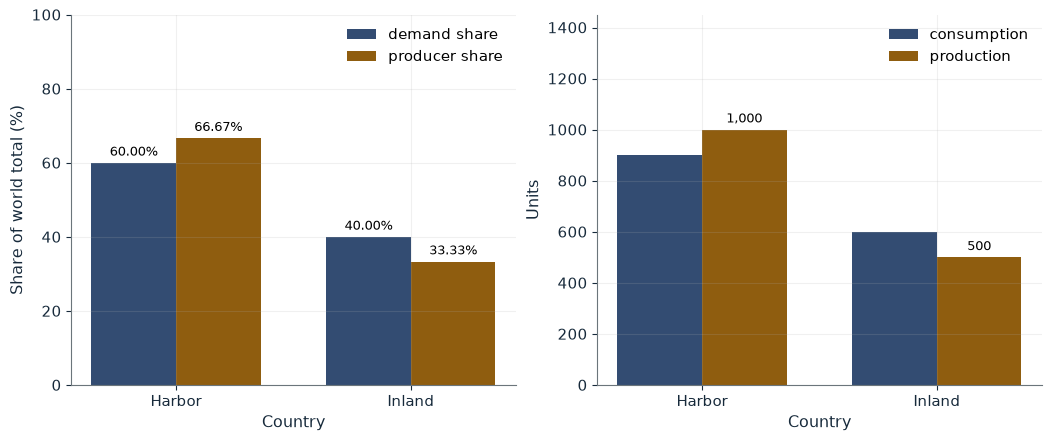

Demand share s_E        60.00%
Producer share s_N      66.67%
Gap s_N - s_E (points)  6.67
Harbor output           1,000
Harbor net exports      100

Worked steps:
  1. s_E = 900 / (900 + 600) = 0.60
  2. s_N = 8 / 12 = 0.6667
  3. Harbor output = 8 x 125 = 1,000
  4. Harbor net exports = 1,000 - 900 = 100
  5. Inland output = 4 x 125 = 500; net exports 500 - 600 = -100

With 8 of 12 producers in Harbor (an assumed equilibrium allocation), s_N = 8 / 12 = 0.6667 against s_E = 0.60. Harbor makes 8 x 125 = 1,000 units and consumes 900, so Harbor exports a net 100 units to Inland. Harbor's producer share exceeds its demand share: the more-than-proportional home-market result.


In [2]:
show(home_market_picture(n_h=8))

Change one input, `n_h`, and hold the others at the book's values:

In [3]:
sweep(home_market_picture, 'n_h', [6, 7, 8, 9], {}, ['Producer share s_N', 'Gap s_N - s_E (points)', 'Harbor net exports'])

n_h | Producer share s_N | Gap s_N - s_E (points) | Harbor net exports
6 | 50.00% | -10.00 | -150
7 | 58.33% | -1.67 | -25
8 | 66.67% | 6.67 | 100
9 | 75.00% | 15.00 | 225


With 8 producers Harbor's production share of 66.67 percent exceeds its 60 percent demand share and it exports a net 100 units. At the equal-demand benchmark allocation of 6, or at 7, Harbor is a net importer.

## 2. Scale mechanism: scale economies without comparative advantage

Every variety costs $C(q)=90+2q$. Autarky runs 8 plants of 75 units; integration runs 4 plants of 150 units.

$$C(75)=90+2(75)=240, \qquad C(150)=90+2(150)=390, \qquad 4(390)=1{,}560$$

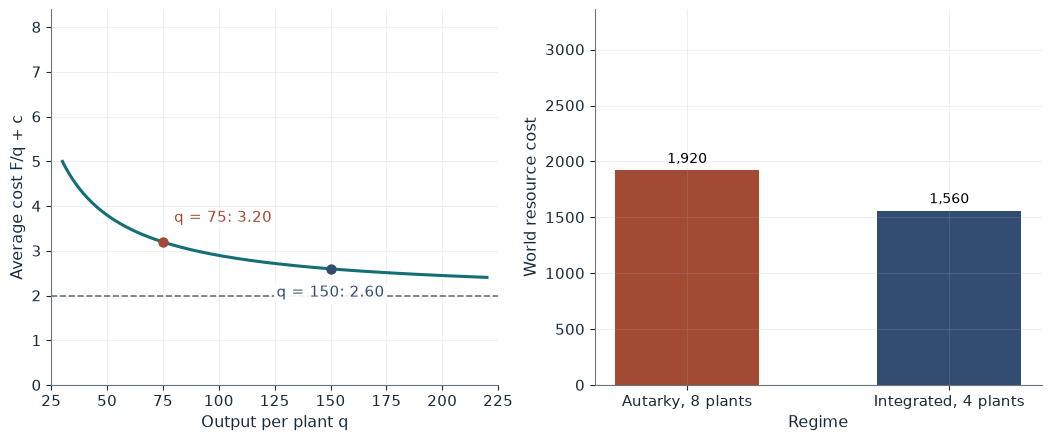

Autarky AC                              3.20
Integrated AC                           2.60
World cost, autarky                     1,920
World cost, integrated                  1,560
Saving                                  360 (18.75%)
Gross intra-industry trade per country  300

Worked steps:
  1. C(75) = 90 + 2(75) = 240; AC = 240 / 75 = 3.20
  2. C(150) = 90 + 2(150) = 390; AC = 390 / 150 = 2.60
  3. Autarky: 8(240) = 1,920; integrated: 4(390) = 1,560
  4. Saving = 1,920 - 1,560 = 360 = 4 x 90, or 360 / 1,920 = 18.75%
  5. Each country exports 2(75) = 150 and imports 150: gross trade 300, net 0

Integration halves the number of plants from 8 to 4, so the world saves four fixed costs: 1,920 - 1,560 = 360 = 4 x 90. Marginal cost 2 is paid on the same 600 units either way, so none of the saving comes from it. Average cost falls from 3.20 to 2.60.


In [4]:
show(scale_picture(fixed=90, c=2))

Change one input, `fixed`, and hold the others at the book's values:

In [5]:
sweep(scale_picture, 'fixed', [30, 90, 150], {'c': 2}, ['Autarky AC', 'Integrated AC', 'Saving'])

fixed | Autarky AC | Integrated AC | Saving
30 | 2.40 | 2.20 | 120 (8.33%)
90 | 3.20 | 2.60 | 360 (18.75%)
150 | 4.00 | 3.00 | 600 (25.00%)


World cost falls from 1,920 to 1,560, a saving of 360 (18.75 percent), exactly the four duplicated fixed costs. Marginal cost does not affect the saving.

## 3. Melitz selection: productivity rises through reallocation

Firms have productivities 1.2, 1.8, 2.7 and 4.5 with sales weights 25, 30, 30 and 15 before trade and 0, 25, 35 and 40 after.

$$\bar\varphi_{s,0}=\frac{232.5}{100}=2.325, \qquad \bar\varphi_{s,1}=\frac{319.5}{100}=3.195$$

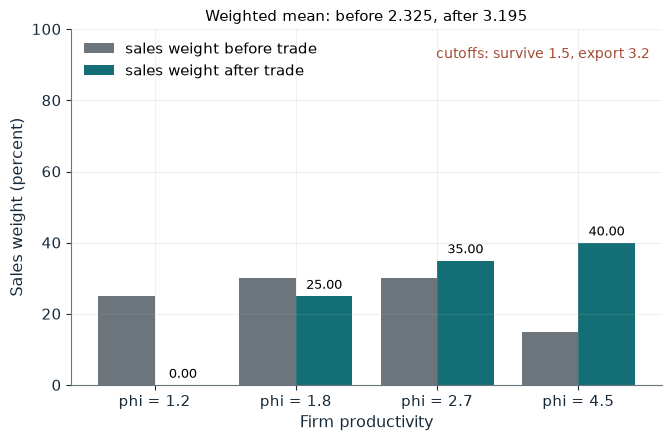

Mean before          2.325
Mean in this regime  3.195
Change               0.870
Change (%)           37.42%

Worked steps:
  1. Before: (25(1.2) + 30(1.8) + 30(2.7) + 15(4.5)) / 100 = 232.5 / 100 = 2.325
  2. Exporter weight 40; the other 60 split 25:35, so 25.00 and 35.00
  3. After: (25.00(1.8) + 35.00(2.7) + 40(4.5)) / 100 = 319.50 / 100 = 3.195
  4. Change = 3.195 - 2.325 = 0.870, or 0.870 / 2.325 = 37.42%

The 1.2 firm exits and the exporter takes 40 percent of sales: 25.00 x 1.8 + 35.00 x 2.7 + 40 x 4.5 = 319.50, so the mean rises from 2.325 to 3.195, a gain of 0.870 (37.42%). No firm became more productive: the rise is all reallocation.


In [6]:
show(melitz_picture(regime='open', wx=40))

Change one input, `wx`, and hold the others at the book's values:

In [7]:
sweep(melitz_picture, 'wx', [20, 40, 60], {'regime': 'open'}, ['Mean in this regime', 'Change', 'Change (%)'])

wx | Mean in this regime | Change | Change (%)
20 | 2.760 | 0.435 | 18.71%
40 | 3.195 | 0.870 | 37.42%
60 | 3.630 | 1.305 | 56.13%


The mean rises by 0.870 (37.42 percent) though no firm changes its productivity: the 1.2 firm exits and sales shift to the exporter.

## 4. Gravity equation: a cut in trade costs

Exports are 160 million, $\sigma=4$, and the iceberg factor falls from 1.30 to 1.22.

$$\frac{X'_{CD}}{X_{CD}}=\left(\frac{1.22}{1.30}\right)^{1-4}=\left(\frac{1.30}{1.22}\right)^3\approx1.2099, \qquad X'_{CD}=160(1.2099)\approx193.58$$

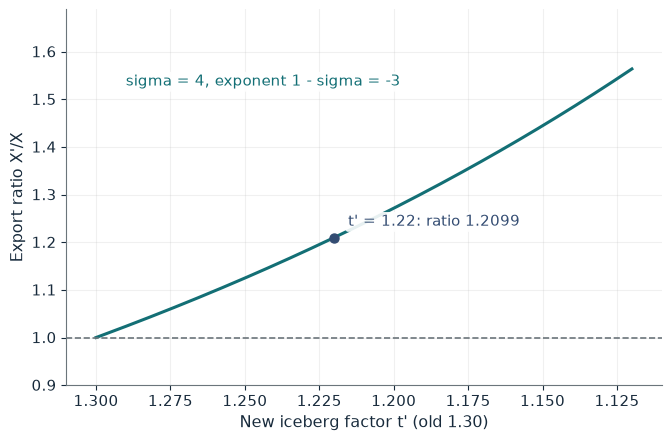

Export ratio           1.2099
New exports (million)  193.58
Cost cut               6.15%
Export rise            20.99%

Worked steps:
  1. X'/X = (1.22 / 1.30)^(1 - 4) = (1.30 / 1.22)^3 = 1.2099
  2. X' = 160 x 1.2099030 = 193.58 million
  3. Cost cut = (1.30 - 1.22) / 1.30 = 6.15%
  4. Export rise = 1.2099 - 1 = 20.99%

With sigma = 4 the trade-cost exponent is -3, so a 6.15% fall in the iceberg factor raises exports by 20.99%: from 160 to 160 x 1.2099030 = 193.58 million, holding incomes and resistance terms fixed.


In [8]:
show(gravity_picture(sigma=4, t1=1.22))

Change one input, `sigma`, and hold the others at the book's values:

In [9]:
sweep(gravity_picture, 'sigma', [2, 4, 6, 8], {'t1': 1.22}, ['Export ratio', 'New exports (million)', 'Export rise'])

sigma | Export ratio | New exports (million) | Export rise
2 | 1.0656 | 170.49 | 6.56%
4 | 1.2099 | 193.58 | 20.99%
6 | 1.3738 | 219.81 | 37.38%
8 | 1.5599 | 249.58 | 55.99%


A 6.15 percent cut in the iceberg factor raises exports by 20.99 percent because trade costs enter with exponent 1 - sigma = -3.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

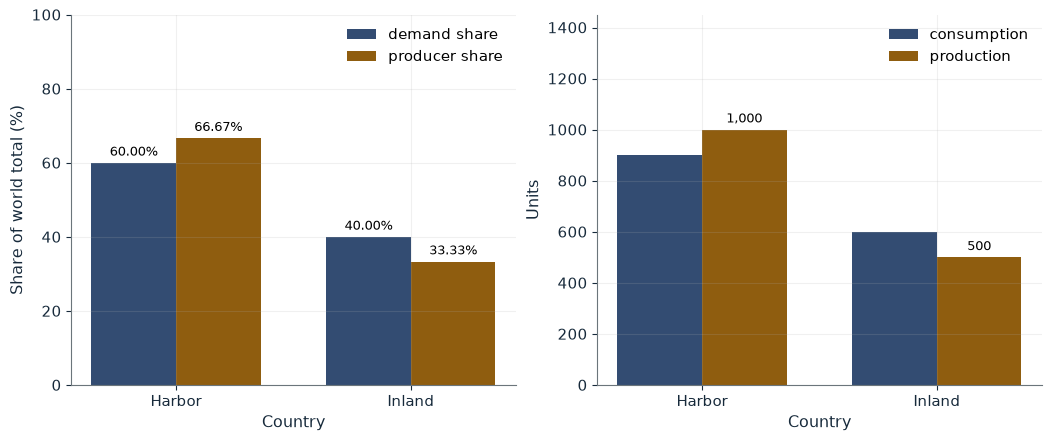

Demand share s_E        60.00%
Producer share s_N      66.67%
Gap s_N - s_E (points)  6.67
Harbor output           1,000
Harbor net exports      100

Worked steps:
  1. s_E = 900 / (900 + 600) = 0.60
  2. s_N = 8 / 12 = 0.6667
  3. Harbor output = 8 x 125 = 1,000
  4. Harbor net exports = 1,000 - 900 = 100
  5. Inland output = 4 x 125 = 500; net exports 500 - 600 = -100

With 8 of 12 producers in Harbor (an assumed equilibrium allocation), s_N = 8 / 12 = 0.6667 against s_E = 0.60. Harbor makes 8 x 125 = 1,000 units and consumes 900, so Harbor exports a net 100 units to Inland. Harbor's producer share exceeds its demand share: the more-than-proportional home-market result.


In [10]:
show(home_market_picture(n_h=8))

## Practice

**1.** If Harbor hosted 7 producers, what are its net exports?

<details><summary>Answer</summary>

7 x 125 = 875 units against 900 consumed: net exports of -25, a small net import.

</details>

**2.** With a fixed cost of 150 and marginal cost 2, what does integration save?

<details><summary>Answer</summary>

Autarky 8(150 + 150) = 2,400; integrated 4(150 + 300) = 1,800; the saving is 600 = 4 x 150.

</details>

**3.** At sigma = 6 with the book's cost cut, what is the export ratio?

<details><summary>Answer</summary>

(1.30/1.22)^5 = 1.3737813, so exports reach 160 x 1.3737813 = 219.81 million.

</details>